<div style="display:flex;align-items:center;gap:30px;margin:18px 0"><img src="images/mcdc.png" alt="MCDC logo" style="width:150px"><img src="images/CivicLabLogo.jpeg" alt="The CivicLab logo" style="width:230px"></div>

## MCDC Connection

The CivicLab, an MCDC community partner, uses data to help people understand public finances. A useful visualization must explain what its numbers represent, what observations are included, and which conclusions require checking the original reports. Here we practice data communication and reproducible design rather than evaluating the effectiveness of TIF policy.

## About This Lesson

A community reader wants to compare Chicago TIF districts. Which district recorded the most spending in a particular year? Is that the same district with the largest ending balance? How can an interactive chart explain the difference?

This lesson uses the [CivicLab–MCDC TIF Illumination project repository](https://github.com/philipayates/chicago2022TIF), which contains financial values extracted from annual public reports. It extends the summer 2026 PDF lesson: that lesson obtains a single record, while this one uses the project's multi-district table to build comparisons. It runs independently from that notebook.

The finished explorer has selectors for year, measure, and district. It displays a within-year comparison and the selected district's history, with definitions, coverage notes, and accessible tables. All figures describe a **frozen 2010–2023 snapshot**, not current finances.

## Learning objectives

By the end of this lesson, you should be able to:

1. Obtain project data at a fixed repository revision and document provenance.
2. Check district-year keys, coverage, and source-review flags.
3. Distinguish annual flows, point-in-time balances, and cumulative measures.
4. Reshape data and construct reproducible rankings with explicit tie handling.
5. Build an interactive Plotly chart with informative labels and hover text.
6. Preserve missing years as gaps instead of silently treating them as zero.
7. Export an offline explorer and verify that selectors update both views.
8. Write a concise, qualified description for a community audience.

**Prerequisites:** pandas selection, sorting, grouping, and basic charts. JavaScript is not required for the core Python analysis; a supplied HTML template handles linked controls in the final export.

**Suggested duration:** Two 75-minute sessions. Parts 1–5 cover data and comparison design. Parts 6–10 cover interaction, export, and communication.

## Setup

Run this notebook from the summer MCDC folder. Original files are under `data/raw/mcdc_tif/`; new results go under `data/processed/tif_explorer/`. Paths are relative to the folder containing this notebook. The source CSV and the `tif_explorer_template.html` file used in Part 8 are downloaded automatically if they are missing. Once packages and these files are present, the lesson runs offline.

In [1]:
# Uncomment only if these packages are missing from your notebook environment.
# %pip install pandas numpy matplotlib plotly requests

In [2]:
from pathlib import Path
import hashlib
import json
import platform
from importlib.metadata import version
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
from plotly.offline import get_plotlyjs
from IPython.display import HTML, display
import requests

raw_dir = Path("data/raw/mcdc_tif")
out_dir = Path("data/processed/tif_explorer")
out_dir.mkdir(parents=True, exist_ok=True)
data_path = raw_dir / "master_TIF_2023.csv"
plt.rcParams.update({"figure.dpi":120, "font.size":11,
                     "axes.spines.top":False, "axes.spines.right":False})

## Part 1 — Obtain the MCDC project snapshot

The source is `TIF_PDF_Parsing/csvs/master_TIF_2023.csv` in `philipayates/chicago2022TIF`. The [project README](https://github.com/philipayates/chicago2022TIF) explains its community connection and variable definitions. The project parsed annual reports and assembled the table; these are not independently re-audited values for every district.

We retrieved the CSV and original README on September 5, 2026 at commit `a7dba68a484f49c682a823a023b6ee7f5cf20473`. A fixed revision avoids silently changing the lesson if the repository's main branch changes. A local SHA-256 checksum records the bytes obtained at preparation time.

To download manually, follow the fixed file URL printed below and save the CSV unchanged in the raw-data folder. The cell downloads only if absent, then verifies its bytes. A matching checksum confirms reproducibility, not scientific or accounting correctness.

In [3]:
COMMIT = "a7dba68a484f49c682a823a023b6ee7f5cf20473"
REPO = "https://github.com/philipayates/chicago2022TIF"
FILE_PATH = "TIF_PDF_Parsing/csvs/master_TIF_2023.csv"
SOURCE_URL = f"{REPO}/blob/{COMMIT}/{FILE_PATH}"
RAW_URL = f"https://raw.githubusercontent.com/philipayates/chicago2022TIF/{COMMIT}/{FILE_PATH}"
EXPECTED_SHA256 = "97c58e7f5871a48eabbcef069eb5a162e72cd3d373e1f5a7fc0f55b68530d39d"
print(RAW_URL)
if not data_path.exists():
    response = requests.get(RAW_URL, timeout=60)
    response.raise_for_status()
    if hashlib.sha256(response.content).hexdigest() != EXPECTED_SHA256:
        raise ValueError("Unexpected file bytes: inspect the revision and response.")
    raw_dir.mkdir(parents=True, exist_ok=True)
    data_path.write_bytes(response.content)
source_hash = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert source_hash == EXPECTED_SHA256
df = pd.read_csv(data_path)
print("Source shape:", df.shape)
display(df.head())

https://raw.githubusercontent.com/philipayates/chicago2022TIF/a7dba68a484f49c682a823a023b6ee7f5cf20473/TIF_PDF_Parsing/csvs/master_TIF_2023.csv
Source shape: (2049, 16)


,tif_name,tif_year,start_year,end_year,tif_number,property_tax_extraction,cumulative_property_tax_extraction,transfers_in,cumulative_transfers_in,expenses,fund_balance_end,transfers_out,distribution,admin_costs,finance_costs,bank
0,35th/Halsted,2010,1997,2021,1,4702898,25175131,0,1743618,801061,19386107,0,0,72520.0,0.0,NaN
1,35th/Halsted,2011,1997,2021,1,5786159,30961290,0,1743618,2010440,21477475,0,2000000,63911.0,0.0,NaN
2,35th/Halsted,2012,1997,2021,1,0,36235145,0,1743618,2502831,23779182,0,905000,93628.0,0.0,NaN
3,35th/Halsted,2013,1997,2021,1,4350228,40585373,0,1743618,6428250,20328678,0,1384000,78254.0,0.0,NaN
4,35th/Halsted,2014,1997,2021,1,4540874,45126247,0,1743618,1948674,22985458,0,0,103592.0,0.0,NaN


## Part 2 — Define the measures before plotting

| Source column | Meaning | Time interpretation |
|---|---|---|
| `property_tax_extraction` | Recorded property-tax increment | Annual flow |
| `expenses` | Recorded expenditures | Annual flow |
| `fund_balance_end` | Recorded ending fund balance | Snapshot |
| `cumulative_property_tax_extraction` | Recorded tax increment accumulated over time | Cumulative amount |

These definitions follow the project documentation. Do not add ending balances or cumulative extraction across years and label the sum as revenue. Transfers can also lead to double counting when combining district inflows. A fund balance does not identify uncommitted money without further information.

The metric dictionary below is used by both the Python charts and the exported explorer. Central definitions prevent a dropdown label from drifting away from its chart's meaning. Amounts remain in nominal dollars; no inflation series or population denominator is added.

In [4]:
metrics = {
    "expenses": {"label":"Annual spending", "kind":"annual flow",
        "description":"Recorded expenditures during the selected reporting year. Nominal dollars."},
    "property_tax_extraction": {"label":"Annual tax extraction", "kind":"annual flow",
        "description":"Recorded property-tax increment for the selected reporting year. Nominal dollars."},
    "fund_balance_end": {"label":"Ending fund balance", "kind":"snapshot",
        "description":"Recorded balance at year-end. It does not establish uncommitted funds."},
    "cumulative_property_tax_extraction": {"label":"Cumulative tax extraction", "kind":"cumulative",
        "description":"Recorded tax extraction accumulated through the selected year, including earlier years. Do not sum it across years."},
}
keys = ["tif_number", "tif_year"]
required = keys + ["tif_name"] + list(metrics)
assert set(required).issubset(df.columns)
data = df[required].copy().sort_values(keys).reset_index(drop=True)
assert data[keys + ["tif_name"]].notna().all().all()
assert not data.duplicated(keys).any(), "Duplicate district-year records require investigation."
for field in list(metrics) + keys:
    data[field] = pd.to_numeric(data[field], errors="raise")
    assert np.isfinite(data[field]).all(), f"Inspect nonfinite values in {field}."
assert (data.groupby("tif_number").tif_name.nunique() == 1).all()
print("Districts:", data.tif_number.nunique())
print("Years:", data.tif_year.min(), "to", data.tif_year.max())

Districts: 178
Years: 2010 to 2023


## Part 3 — Coverage and source-review flags

A tidy table can still contain extraction errors or revised accounting values. We first count available district-year records. A declining record count is not evidence of declining spending or a complete history of district closures.

Two simple screening rules flag negative stored values and cases where the difference between consecutive cumulative tax amounts disagrees with annual tax extraction by more than $1. Restatements, definitions, and parsing errors can all require investigation. These checks are **review prompts**, not a complete accounting reconciliation. We keep every original value and do not automatically “repair” a flagged row.

,recorded_districts
tif_year,
2010,165
2011,164
2012,163
2013,155
2014,154
2015,147
2016,148
2017,145
2018,145


Rows flagged by the tax-difference check: 28
Rows containing a negative selected value: 58


,tif_number,tif_year,tif_name,review_note
2,1,2012,35th/Halsted,Annual tax extraction differs from the change ...
16,2,2012,41st/King,Annual tax extraction differs from the change ...
17,2,2013,41st/King,Annual tax extraction differs from the change ...
100,15,2011,Chatham-Ridge,Negative stored value: inspect original report
106,18,2011,Division/North Branch,Annual tax extraction differs from the change ...


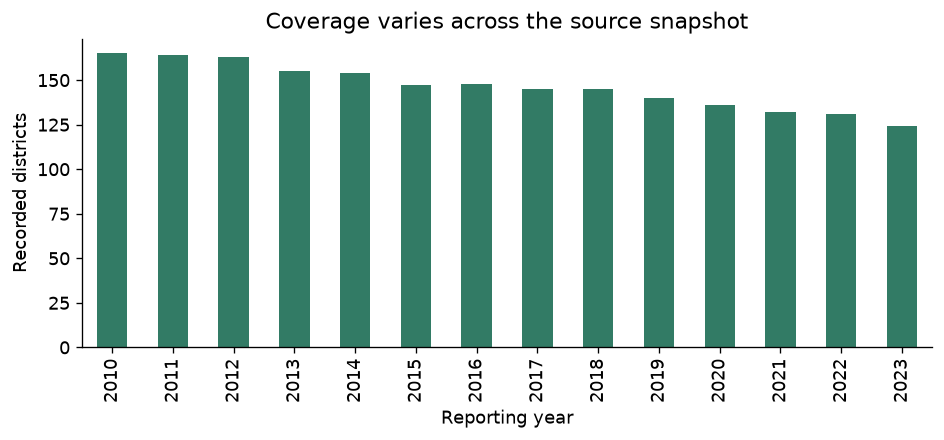

In [5]:
coverage = data.groupby("tif_year").agg(recorded_districts=("tif_number", "nunique"))
display(coverage)
previous_year = data.groupby("tif_number").tif_year.shift()
cumulative_change = data.groupby("tif_number").cumulative_property_tax_extraction.diff()
consecutive = data.tif_year - previous_year == 1
data["tax_difference_flag"] = consecutive & ((cumulative_change - data.property_tax_extraction).abs() > 1)
data["negative_value_flag"] = (data[list(metrics)] < 0).any(axis=1)
data["review_note"] = [
    "; ".join(note for flag, note in [
        (negative, "Negative stored value: inspect original report"),
        (difference, "Annual tax extraction differs from the change in cumulative extraction")
    ] if flag)
    for negative, difference in zip(data.negative_value_flag, data.tax_difference_flag)
]
print("Rows flagged by the tax-difference check:", data.tax_difference_flag.sum())
print("Rows containing a negative selected value:", data.negative_value_flag.sum())
display(data.loc[data.review_note.ne(""), keys + ["tif_name", "review_note"]].head())
fig, ax = plt.subplots(figsize=(8, 3.8))
coverage.plot.bar(ax=ax, legend=False, color="#327b65")
ax.set(xlabel="Reporting year", ylabel="Recorded districts", title="Coverage varies across the source snapshot")
fig.tight_layout()
plt.show()

### Connection to the PDF lesson

The three core 2019 Kinzie values below match the reference values used in the companion PDF lesson. This narrow cross-check does not verify every field, district, or year. Additional fields can disagree across extraction workflows and should be checked against the original report before use.

In [6]:
kinzie = data.loc[(data.tif_number == 52) & (data.tif_year == 2019)].iloc[0]
reference = {"property_tax_extraction":41093833, "expenses":17400749, "fund_balance_end":124495431}
cross_check = pd.DataFrame({"project_table":[kinzie[k] for k in reference],
                            "companion_lesson_reference":list(reference.values())}, index=reference)
cross_check["match"] = cross_check.project_table == cross_check.companion_lesson_reference
display(cross_check)
assert cross_check.match.all()

,project_table,companion_lesson_reference,match
property_tax_extraction,41093833,41093833,True
expenses,17400749,17400749,True
fund_balance_end,124495431,124495431,True


## Part 4 — Reshape for comparison

The original table has one row per district-year and one column per measure. `melt` produces one row per district-year-measure. The amount remains numeric, and the measure name becomes a column. Keep the identifier and year together when filtering.

We preserve the original wide table too. A long table is useful for plotting, but summing its entire amount column would mix different concepts and double count information.

In [7]:
long_data = data.melt(id_vars=keys + ["tif_name"], value_vars=list(metrics),
                      var_name="measure", value_name="amount")
long_data["label"] = long_data.measure.map({k:v["label"] for k,v in metrics.items()})
assert len(long_data) == len(data) * len(metrics)
display(long_data.head())

,tif_number,tif_year,tif_name,measure,amount,label
0,1,2010,35th/Halsted,expenses,801061,Annual spending
1,1,2011,35th/Halsted,expenses,2010440,Annual spending
2,1,2012,35th/Halsted,expenses,2502831,Annual spending
3,1,2013,35th/Halsted,expenses,6428250,Annual spending
4,1,2014,35th/Halsted,expenses,1948674,Annual spending


## Part 5 — Rank recorded districts within one year

Choose the comparison before sorting. Here we compare recorded spending in 2023. Larger dollars do not mean better performance or more benefit per resident. The table has no denominator suitable for those claims.

Equal amounts share the minimum rank. We sort tied values by district ID to make display order deterministic. A top-ten chart has ten rows even if a tie crosses the cutoff; report that choice.

,tif_number,tif_year,tif_name,expenses,rank
381,52,2023,Kinzie Industrial Corridor,46120349,1
98,13,2023,Bryn Mawr/Broadway,27299751,2
1150,109,2023,Lawrence/Broadway,27198658,3
1635,147,2023,LaSalle Central,27071471,4
2022,180,2023,Red Purple Modernization Phase One (Transit TIF),25398909,5
830,86,2023,Central West,18743562,6
1767,157,2023,Hollywood/Sheridan,17470110,7
1164,110,2023,Wilson Yard,12664517,8
528,63,2023,Canal/Congress,9153567,9
1659,149,2023,Stevenson Brighton,8816950,10


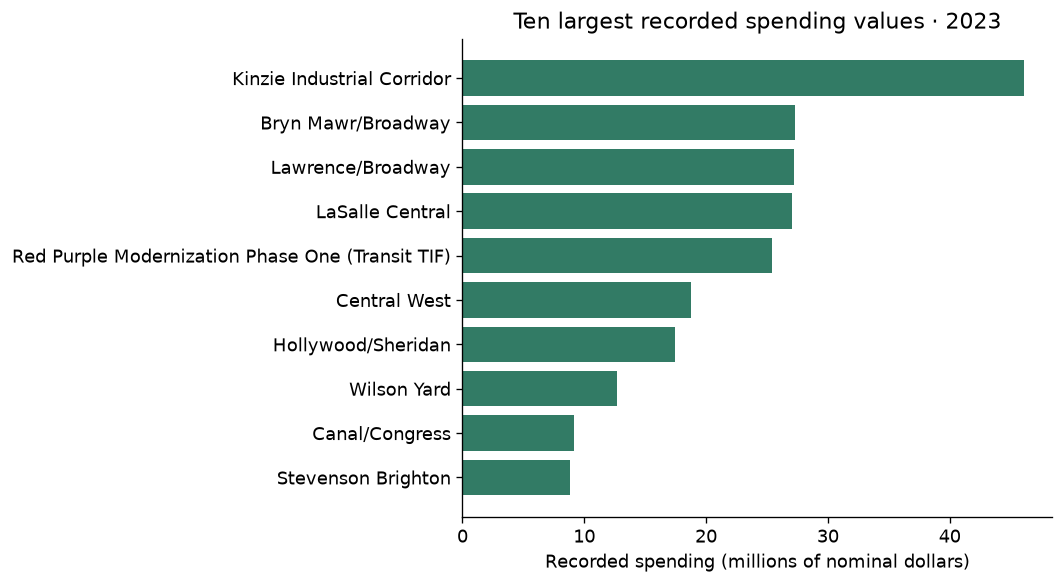

In [8]:
def rank_districts(frame, year, measure):
    if measure not in metrics:
        raise ValueError("Choose a measure from the dictionary.")
    subset = frame.loc[frame.tif_year == year, keys + ["tif_name", measure]].dropna(subset=[measure]).copy()
    if subset.empty:
        raise ValueError("No recorded values for this year.")
    subset["rank"] = subset[measure].rank(method="min", ascending=False).astype(int)
    return subset.sort_values([measure, "tif_number"], ascending=[False, True])

year = 2023
measure = "expenses"
ranked = rank_districts(data, year, measure)
display(ranked.head(10))
assert ranked[measure].is_monotonic_decreasing
fig, ax = plt.subplots(figsize=(9, 5))
top = ranked.head(10).iloc[::-1]
ax.barh(top.tif_name, top[measure] / 1e6, color="#327b65")
ax.set(xlabel="Recorded spending (millions of nominal dollars)",
       title=f"Ten largest recorded spending values · {year}")
fig.tight_layout()
plt.show()

### The measure changes the ranking

Compare annual spending with ending balance for the same year. These are different questions, not interchangeable rankings of district quality. A spending flow can use funds accumulated in earlier years, and a balance can reflect commitments absent from this dataset.

In [9]:
balance_ranks = rank_districts(data, year, "fund_balance_end")
rank_comparison = ranked[["tif_number", "tif_name", "rank"]].rename(columns={"rank":"spending_rank"}).merge(
    balance_ranks[["tif_number", "rank"]].rename(columns={"rank":"balance_rank"}),
    on="tif_number", validate="one_to_one")
display(rank_comparison.head(10))

,tif_number,tif_name,spending_rank,balance_rank
0,52,Kinzie Industrial Corridor,1,1
1,13,Bryn Mawr/Broadway,2,86
2,109,Lawrence/Broadway,3,24
3,147,LaSalle Central,4,2
4,180,Red Purple Modernization Phase One (Transit TIF),5,56
5,86,Central West,6,6
6,157,Hollywood/Sheridan,7,59
7,110,Wilson Yard,8,34
8,63,Canal/Congress,9,4
9,149,Stevenson Brighton,10,41


## Part 6 — Add hover information with Plotly

Interactivity helps readers inspect exact values. The bar length shows magnitude, while hover text supplies the district and dollar amount. We retain a zero baseline and avoid decorating dollar amounts as percentages.

The same Python function can be called with another year or measure. This HTML export embeds Plotly's JavaScript, allowing offline use. It is larger than an export that relies on a remote script, but it does not require a live Python kernel.

In [10]:
def comparison_figure(frame, year, measure):
    top = rank_districts(frame, year, measure).head(10).iloc[::-1]
    figure = px.bar(top, x=measure, y="tif_name", orientation="h",
        title=f"{metrics[measure]['label']} · {year} · ten largest recorded values",
        labels={measure:"Nominal dollars", "tif_name":"District"},
        color_discrete_sequence=["#327b65"])
    figure.update_traces(hovertemplate="%{y}<br>$%{x:,.0f}<extra></extra>")
    figure.update_xaxes(tickprefix="$", rangemode="tozero")
    figure.update_layout(template="plotly_white", height=520, margin=dict(l=15,r=30,t=70,b=60))
    return figure

interactive_comparison = comparison_figure(data, year, measure)
interactive_comparison.write_html(out_dir / "spending_2023_interactive.html", include_plotlyjs=True)
display(HTML(interactive_comparison.to_html(full_html=False, include_plotlyjs="cdn")))

## Part 7 — Show a district over time without inventing missing values

Construct a full year index, then reindex a district's history onto it. Missing district-years become `NaN`, so the line shows gaps. An absent record may reflect a district's lifespan, unavailable reporting, or an extraction gap. It is not a zero.

A larger nominal amount in a later year does not establish growth in purchasing power. Compare nominal values transparently; an inflation-adjusted extension would require a documented price index and base year.

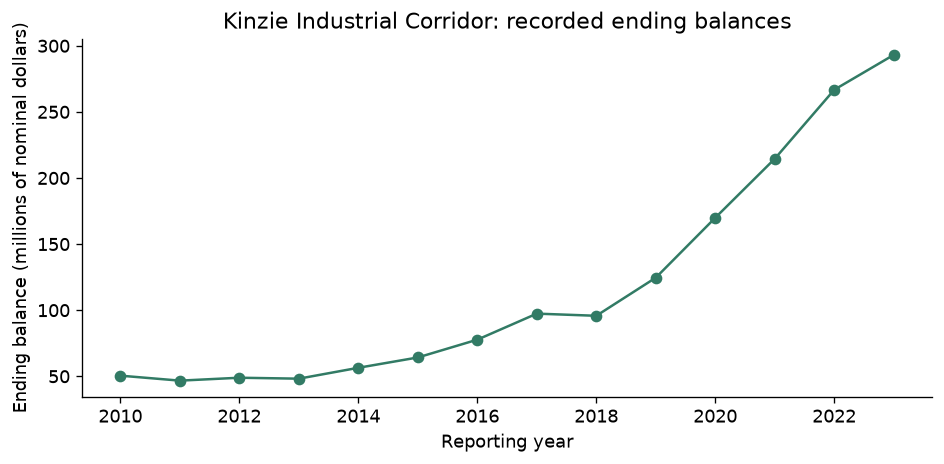

,recorded_spending
tif_year,
2010,NaN
2011,NaN
2012,NaN
2013,NaN
2014,NaN
2015,NaN
2016,NaN
2017,NaN
2018,NaN


In [11]:
years = list(range(int(data.tif_year.min()), int(data.tif_year.max()) + 1))
def district_history(frame, district_id, measure):
    return frame.loc[frame.tif_number == district_id].set_index("tif_year")[measure].reindex(years)

district_id = 52
history = district_history(data, district_id, "fund_balance_end")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(history.index, history / 1e6, "o-", color="#327b65")
ax.set(xlabel="Reporting year", ylabel="Ending balance (millions of nominal dollars)",
       title="Kinzie Industrial Corridor: recorded ending balances")
fig.tight_layout()
plt.show()
# A real missing-record case in this source: Red Line Extension has only 2022–2023 rows.
new_district_history = district_history(data, 186, "expenses")
assert new_district_history.loc[2010:2021].isna().all()
display(new_district_history.rename("recorded_spending").to_frame())

## Part 8 — Export the linked explorer

The supplied `tif_explorer_template.html` handles browser controls. If it is not beside the notebook, the next cell downloads it from the [public lesson repository](https://github.com/Lizhen0909/mcdc_2026su) and verifies its checksum. Python supplies the audited data and metric dictionary. The template filters by year for the comparison, uses the district selector for history, and applies the measure selector to both. It shows a missing-record message when that district-year is absent.

This separates the analysis from interface wiring: students can change definitions and data preparation in Python without first learning JavaScript. The template remains available for an optional extension. It includes keyboard-operable selectors, exact-value tables, source notes, and a highlighted selected district where it appears in the top ten.

Embedding the data and plotting library creates a standalone file. Sharing it shares all included rows, not only those currently selected. These project data are public; do not reuse this pattern with confidential records without addressing that distinction.

In [12]:
TEMPLATE_URL = "https://raw.githubusercontent.com/Lizhen0909/mcdc_2026su/main/tif_explorer_template.html"
TEMPLATE_SHA256 = "9659f082072ebe9922b1fbc80cd79d7a19cb8224779de55ee83c11bc2346f9ab"
template_path = Path("tif_explorer_template.html")
if not template_path.exists():
    response = requests.get(TEMPLATE_URL, timeout=60)
    response.raise_for_status()
    if hashlib.sha256(response.content).hexdigest() != TEMPLATE_SHA256:
        raise ValueError("Unexpected template bytes: inspect the lesson repository.")
    template_path.write_bytes(response.content)
template = template_path.read_text()
# JSON uses null for missing values. Escape '<' so data cannot terminate a script element.
records_json = data.to_json(orient="records").replace("<", "\u003c")
metrics_json = json.dumps(metrics).replace("<", "\u003c")
explorer_html = (template.replace("__DATA_JSON__", records_json)
    .replace("__METRICS_JSON__", metrics_json)
    .replace("__SOURCE_URL__", SOURCE_URL)
    .replace("__PLOTLY_JS__", get_plotlyjs()))
explorer_path = Path("chicago_tif_explorer.html")
explorer_path.write_text(explorer_html)
print("Open", explorer_path, "in a browser for linked year, measure, and district controls.")

Open chicago_tif_explorer.html in a browser for linked year, measure, and district controls.


## Part 9 — Check the views against the data

Test both normal selections and missing-record cases. A visually polished chart can still show stale values if one selector fails to update another view. The checks below establish expected values for manual browser verification.

1. Select **2023 / Annual spending / Kinzie Industrial Corridor**. Confirm the value and rank match the first expected row below.
2. Switch to **Ending fund balance**. The chart labels, comparison, and history must all change.
3. Select **2010 / Annual spending / Red Line Extension**. Confirm that the status says no recorded value, rather than $0, while later history remains visible.
4. Select **2012 / Annual tax extraction / 35th/Halsted**. Confirm that the stored zero remains visible alongside a source-review note.
5. Open each data table and compare its values with the plots. Try keyboard selection and a narrow browser window.

In [13]:
expected = []
for test_year, test_measure, test_id in [(2023,"expenses",52), (2023,"fund_balance_end",52),
                                        (2010,"expenses",186), (2012,"property_tax_extraction",1)]:
    table = rank_districts(data, test_year, test_measure)
    selected = table.loc[table.tif_number == test_id]
    expected.append({"year":test_year, "measure":test_measure, "district_id":test_id,
                     "value":None if selected.empty else int(selected.iloc[0][test_measure]),
                     "rank":None if selected.empty else int(selected.iloc[0]["rank"])})
display(pd.DataFrame(expected))
assert expected[2]["value"] is None
assert data.loc[(data.tif_number==1)&(data.tif_year==2012), "tax_difference_flag"].item()

,year,measure,district_id,value,rank
0,2023,expenses,52,46120349.0,1.0
1,2023,fund_balance_end,52,293029705.0,1.0
2,2010,expenses,186,NaN,NaN
3,2012,property_tax_extraction,1,0.0,144.0


## Part 10 — Preserve the data story and provenance

A companion CSV lets readers inspect the values outside the chart. Save the definitions, review flags, coverage table, source revision, and package versions. Exporting an attractive screenshot alone would hide much of that context.

In [14]:
data.to_csv(out_dir / "explorer_data.csv", index=False)
long_data.to_csv(out_dir / "tif_measures_long.csv", index=False)
coverage.to_csv(out_dir / "year_coverage.csv")
data.loc[data.review_note.ne("")].to_csv(out_dir / "source_review_flags.csv", index=False)
(out_dir / "metric_definitions.json").write_text(json.dumps(metrics, indent=2))
(out_dir / "expected_selections.json").write_text(json.dumps(expected, indent=2))
provenance = {"repository":REPO, "commit":COMMIT, "source_url":SOURCE_URL,
    "source_sha256":source_hash, "retrieved":"2026-09-05", "n_records":len(data),
    "n_districts":int(data.tif_number.nunique()), "years":years,
    "amounts":"Nominal dollars, no inflation adjustment", "source_values_modified":False,
    "scope":"Project-parsed data, not an independent audit of all original reports",
    "python":platform.python_version(),
    "packages":{package:version(package) for package in ["pandas","numpy","matplotlib","plotly"]}}
(out_dir / "analysis_provenance.json").write_text(json.dumps(provenance, indent=2))
restored = pd.read_csv(out_dir / "explorer_data.csv")
pd.testing.assert_frame_equal(restored[required], data[required], check_dtype=False)
print("Exported explorer, data, definitions, review flags, and provenance.")

Exported explorer, data, definitions, review flags, and provenance.


## Part 11 — Exercises

### Exercise 1: Two questions, two measures

Choose one district and year. Compare its spending rank with its ending-balance rank. Explain what each ranking measures and why neither is a ranking of public benefit.

### Exercise 2: Tie handling

Find a year and measure with tied values. Change the top-ten function to include every district tied at the cutoff. Report how many bars the revised chart would contain. Do not alter the underlying values.

### Exercise 3: A common set of districts

Find district IDs represented in both 2010 and 2023. Compare recorded spending totals for that common set with the totals using all available records in each year. Explain why changing coverage and nominal dollars limit interpretation. A common set also excludes districts that appear in only one year.

### Exercise 4: Trace a flagged row

Choose one source-review flag and locate its original annual report. Document whether it is an extraction problem, a revision, or unresolved. Preserve the original value and any proposed correction in separate columns with evidence. Do not replace values merely to satisfy the screening rule.

### Exercise 5: Improve a chart caption

Write 80–120 words describing one selected view. Include the measure, year, data source, comparison universe, and one limitation. Replace claims such as “best district” or “money available” with statements the data actually support.

### Exercise 6: Add a measure

Add `transfers_out` from the source table to the definitions and analysis. Explain its annual-flow meaning, rebuild the exports, and check both views and tables. Do not add it to spending or revenue totals without checking the accounting definitions.

### Challenge: A Python dashboard framework

Rebuild the three selectors using Streamlit or Dash, reusing the same ranking and history functions. Preserve missing values, source notes, and review flags. Compare the need for a running server with the offline HTML approach. Keep deployment separate from local classroom development.

## Part 12 — Reflection and discussion

1. Why does a checksum not establish that the financial values are correct?
2. Why is summing cumulative values across years misleading?
3. What are the consequences of replacing absent district-years with zero?
4. When can a top-ten chart hide an important pattern?
5. What evidence would be needed to evaluate equity or community benefit?
6. What source documentation should accompany a chart shared outside class?

### MCDC Connection: A Data Product People Can Question

The explorer helps a reader inspect recorded values and formulate better questions. Its definitions, tables, and provenance make it possible to challenge an interpretation or trace a number. Interactive controls should support understanding, not make uncertain data appear more authoritative.

## Acknowledgment and source notes

This lesson builds on the CivicLab–MCDC TIF Illumination and Analysis project and follows the summer 2026 lesson format. The original repository README is preserved under `data/raw/mcdc_tif/README_original.md`. The CSV contains 2,049 district-year rows for 178 districts and years 2010–2023. It is a fixed teaching snapshot, not a claim of complete reporting or current data. Repository availability alone does not establish a blanket license for every project asset; preserve attribution and consult source terms before broader republication.

- [Project repository](https://github.com/philipayates/chicago2022TIF)
- [MCDC project description](https://sites.northwestern.edu/mcdc/tax-increment-financing-illumination-and-analysis/)
- [City of Chicago annual reports](https://www.chicago.gov/city/en/depts/dcd/supp_info/tif-district-annual-reports-2004-present.html)
- [Plotly bar-chart documentation](https://plotly.com/python/bar-charts/)
- [Plotly interactive HTML export](https://plotly.com/python/interactive-html-export/)